SANTIAGO DIE MOREJÓN - 24/04/2026 - IA - Entregable 2 Adicional 2 - CPU vs GPU

# Notebook 3: Comparativa CPU vs GPU
En este notebook entrenamos el mismo modelo (ResNet18) con el mismo dataset de imágenes satelitales (cloudy, desert, green_area, water) primero usando CPU y luego usando GPU, y comparamos los tiempos de entrenamiento obtenidos.

## 0. Instalación y carga de librerías

In [1]:
!pip install fastai -Uq

In [2]:
from fastai.vision.all import *
import os
import shutil
import time
import torch
from sklearn.model_selection import train_test_split

## 1. Preparación del dataset

Descargamos y organizamos el mismo dataset satelital del notebook principal.

In [3]:
!wget DATA_URL -O archive.zip
!unzip -q archive.zip

--2026-04-27 21:24:47--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.111.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 22836290 (22M) [application/zip]
Saving to: ‘archive.zip’

archive.zip         100%[===================>]  21.78M  --.-KB/s    in 0.09s   

2026-04-27 21:24:48 (249 MB/s) - ‘archive.zip’ saved [22836290/22836290]



In [4]:
os.makedirs('/content/data/satellite/train', exist_ok=True)
os.makedirs('/content/data/satellite/test', exist_ok=True)

for c in ['cloudy', 'desert', 'green_area', 'water']:
    os.makedirs(f'/content/data/satellite/train/{c}', exist_ok=True)
    os.makedirs(f'/content/data/satellite/test/{c}', exist_ok=True)

In [5]:
path = Path('/content/data')

In [6]:
for im in verify_images(get_image_files('/content/data')):
    os.remove(str(im))

In [7]:
from sklearn.model_selection import train_test_split

trainCloudy,   testCloudy   = train_test_split(get_image_files(path/'cloudy'),    test_size=0.2, random_state=15)
trainDesert,   testDesert   = train_test_split(get_image_files(path/'desert'),    test_size=0.2, random_state=15)
trainGreen,    testGreen    = train_test_split(get_image_files(path/'green_area'),test_size=0.2, random_state=15)
trainWater,    testWater    = train_test_split(get_image_files(path/'water'),     test_size=0.2, random_state=15)

In [8]:
for x in trainCloudy:
    shutil.move(str(x), path/('satellite/train/cloudy/'+x.name))

for x in trainDesert:
    shutil.move(str(x), path/('satellite/train/desert/'+x.name))

for x in trainGreen:
    shutil.move(str(x), path/('satellite/train/green_area/'+x.name))

for x in trainWater:
    shutil.move(str(x), path/('satellite/train/water/'+x.name))


In [9]:
for x in testCloudy:
    shutil.move(str(x), path/('satellite/test/cloudy/'+x.name))

for x in testDesert:
    shutil.move(str(x), path/('satellite/test/desert/'+x.name))

for x in testGreen:
    shutil.move(str(x), path/('satellite/test/green_area/'+x.name))

for x in testWater:
    shutil.move(str(x), path/('satellite/test/water/'+x.name))

In [10]:
shutil.rmtree(path/'cloudy')
shutil.rmtree(path/'desert')
shutil.rmtree(path/'green_area')
shutil.rmtree(path/'water')

## 2.Entrenamiento y medición del tiempo
Entrenamos el modelo registrando el tiempo total, el tiempo por época y el tiempo de inferencia.

In [11]:
# Parámetros fijos para ambas ejecuciones
IMG_SIZE  = 224
BATCH_SIZE = 32
EPOCHS     = 3      #para no esperar demasiado en CPU
SEED       = 42

Imágenes de entrenamiento: 3604
Imágenes de validación:    900


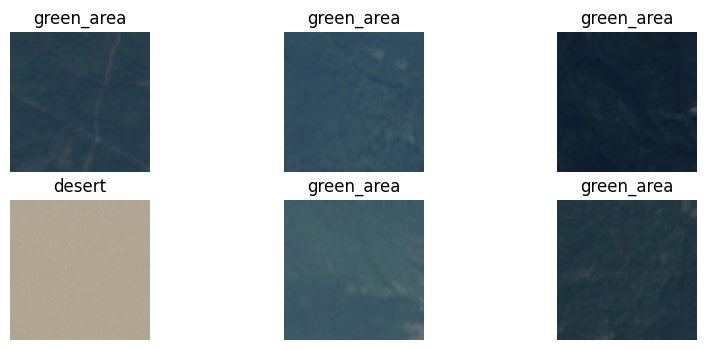

In [12]:
dls = ImageDataLoaders.from_folder(path/'satellite'/'train',
    valid_pct=0.2,
    seed=SEED,
    item_tfms=Resize(IMG_SIZE),
    batch_tfms=aug_transforms(size=IMG_SIZE, min_scale=0.75),
    bs=BATCH_SIZE
)

print(f"Imágenes de entrenamiento: {len(dls.train_ds)}")
print(f"Imágenes de validación:    {len(dls.valid_ds)}")
dls.show_batch(max_n=6, figsize=(10, 4))

In [13]:
learn = vision_learner(dls, resnet18, metrics=[accuracy, error_rate])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s]


* CPU

In [15]:
t0 = time.time()
learn.fine_tune(EPOCHS)
tiempo_total = round(time.time() - t0, 2)
print(f"Tiempo total (Cpu): {tiempo_total}s")

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.294838,0.031001,0.988889,0.011111,08:22


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.113068,0.036280,0.991111,0.008889,11:33
1,0.062479,0.009986,0.993333,0.006667,11:44
2,0.031313,0.012483,0.996667,0.003333,12:17


Tiempo total (Cpu): 2639.33s


* GPU

In [14]:
t0 = time.time()
learn.fine_tune(EPOCHS)
tiempo_total = round(time.time() - t0, 2)
print(f"Tiempo total (GPU): {tiempo_total}s")

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.315596,0.045176,0.987778,0.012222,00:15


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.111472,0.027366,0.991111,0.008889,00:16
1,0.073833,0.009407,0.994444,0.005556,00:17
2,0.045931,0.006584,0.996667,0.003333,00:16


Tiempo total (GPU): 67.31s


Ahora el tiempo inferencia sobre el conjunto de test

* CPU

In [16]:
test_dl = dls.test_dl(get_image_files(path/'satellite'/'test'))
n = len(get_image_files(path/'satellite'/'test'))

t0 = time.time()
learn.get_preds(dl=test_dl)
tiempo_inf = round((time.time() - t0), 2)

print(f"Inferencia (CPU): {tiempo_inf}s | {round(tiempo_inf/n*1000, 2)} ms/imagen")

Inferencia (CPU): 75.82s | 67.28 ms/imagen


* GPU

In [15]:
test_dl = dls.test_dl(get_image_files(path/'satellite'/'test'))
n = len(get_image_files(path/'satellite'/'test'))

t0 = time.time()
learn.get_preds(dl=test_dl)
tiempo_inf = round((time.time() - t0), 2)

print(f"Inferencia (GPU): {tiempo_inf}s | {round(tiempo_inf/n*1000, 2)} ms/imagen")

Inferencia (GPU): 2.58s | 2.29 ms/imagen


## 3. Comparativa CPU vs GPU

In [17]:
resultados = {
    'Dispositivo': ['CPU', 'GPU'],
    'Tiempo Entrenamiento (s)':[2639.33, 67.31],
    'Accuracy': [0.9967, 0.9967],
    'Tiempo Inferencia (s)': [75.82, 2.58],
    'ms/imagen': [67.28, 2.29],
}

In [18]:
df = pd.DataFrame(resultados)
print(df.to_string(index=False))

Dispositivo  Tiempo Entrenamiento (s)  Accuracy  Tiempo Inferencia (s)  ms/imagen
        CPU                   2639.33    0.9967                  75.82      67.28
        GPU                     67.31    0.9967                   2.58       2.29


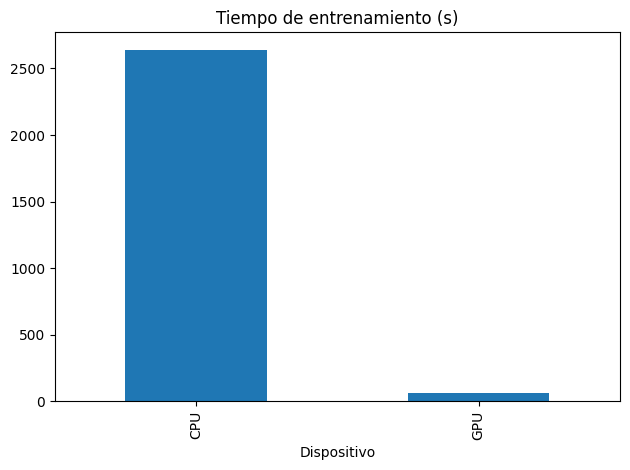

In [19]:
df.plot.bar(x='Dispositivo', y='Tiempo Entrenamiento (s)', legend=False)
plt.title('Tiempo de entrenamiento (s)')
plt.tight_layout()
plt.show()

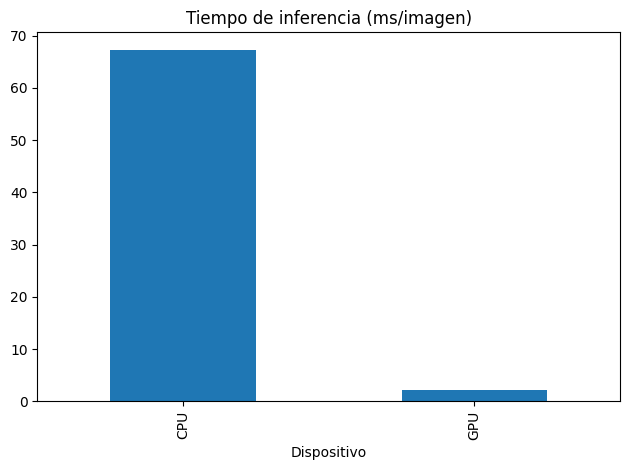

In [20]:
df.plot.bar(x='Dispositivo', y='ms/imagen', legend=False)
plt.title('Tiempo de inferencia (ms/imagen)')
plt.tight_layout()
plt.show()

## 4. Conclusiones

La comparativa confirma que la GPU acelera el entrenamiento  y la
inferencia  respecto a la CPU, pasando de 2639s a 67s en entrenamiento
y de 67.28ms a 2.29ms por imagen en inferencia.

Lo más relevante es que el accuracy final es idéntico en ambos casos (0.9967),
lo que demuestra que el dispositivo no afecta a la calidad del modelo, solo
al tiempo necesario para obtenerlo.

Para un dataset de este tamaño, entrenar en CPU es viable pero poco práctico
(44 minutos frente a poco más de 1 minuto en GPU). La diferencia se ampliaría
considerablemente con datasets más grandes, más épocas o arquitecturas más
profundas, donde el entrenamiento en CPU pasaría de ser lento a ser
directamente inviable.